# Chapitre 15 - Forêts aléatoires (1) : définition, algorithme, erreur *out-of-bag*

Ce premier notebook présente les **forêts aléatoires** (*random forests*, Breiman 2001),
sections 15.1 à 15.3.1 du livre :

1. rappel sur le *bagging* et calcul de la variance d'une moyenne de variables corrélées
   (formule (15.1)) ;
2. l'algorithme 15.1 et une implémentation « à la main » à partir d'arbres de régression ;
3. l'application aux données **spam** et l'erreur **out-of-bag** (figure 15.4) ;
4. la comparaison avec le *bagging* et le *boosting* sur spam (figure 15.1) et sur la
   simulation des « sphères emboîtées » (figure 15.2).

Le second notebook traite de l'importance des variables, des proximités et de l'analyse
biais/variance (section 15.4).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch15_forets as rf
set_style()

## 1. Point de départ : le *bagging*

Rappelons le *bagging* (section 8.7). On dispose d'un échantillon d'apprentissage
$\mathbf Z=\{(x_1,y_1),\dots,(x_N,y_N)\}$. Pour $b=1,\dots,B$ :

- on tire un **échantillon bootstrap** $\mathbf Z^{*b}$ : $N$ observations tirées
  **avec remise** dans $\mathbf Z$ ;
- on ajuste un prédicteur $\hat f^{*b}$ (ici un arbre) sur $\mathbf Z^{*b}$.

Le prédicteur « bagué » est la moyenne $\hat f_{\rm bag}(x)=\frac1B\sum_{b=1}^B \hat f^{*b}(x)$
(en régression), ou le vote majoritaire des $\hat f^{*b}(x)$ (en classification).

> **Intuition.** Un arbre profond a un **faible biais** (il peut épouser des structures
> compliquées) mais une **forte variance** : changer quelques observations modifie les
> premières coupures et donc tout l'arbre. Moyenner beaucoup d'arbres « bruités mais à
> peu près sans biais » réduit la variance.

Les arbres $\hat f^{*1},\dots,\hat f^{*B}$ sont **identiquement distribués** (i.d.) :
ils sont construits par le même procédé aléatoire. Par linéarité de l'espérance,
$$\mathbb E\big[\hat f_{\rm bag}(x)\big]=\frac1B\sum_{b=1}^B\mathbb E\big[\hat f^{*b}(x)\big]=\mathbb E\big[\hat f^{*1}(x)\big],$$
donc **le biais du bagging est celui d'un seul arbre** : le seul gain possible porte sur
la variance. (Le boosting, au contraire, construit des arbres adaptativement pour réduire
le biais ; ses arbres ne sont pas i.d.)

## 2. Variance d'une moyenne de variables corrélées - formule (15.1)

Soient $T_1,\dots,T_B$ des variables aléatoires de même variance $\sigma^2$ et de
corrélation deux à deux $\rho$, c'est-à-dire $\operatorname{Cov}(T_b,T_{b'})=\rho\sigma^2$
pour $b\neq b'$. On développe la variance de la moyenne par bilinéarité de la covariance :
$$
\begin{aligned}
\operatorname{Var}\Big(\frac1B\sum_{b=1}^B T_b\Big)
&=\frac1{B^2}\Big(\sum_{b=1}^B\operatorname{Var}(T_b)+\sum_{b\neq b'}\operatorname{Cov}(T_b,T_{b'})\Big)\\
&=\frac1{B^2}\big(B\sigma^2+B(B-1)\rho\sigma^2\big)
=\rho\sigma^2+\frac{1-\rho}{B}\sigma^2 .
\end{aligned}
$$
C'est la formule (15.1) du livre (la démonstration détaillée et le cas $\rho<0$ font
l'objet de l'exercice 15.1).

> **À retenir.** Quand $B\to\infty$, le second terme disparaît mais le premier,
> $\rho\sigma^2$, **reste** : la corrélation entre les arbres limite le bénéfice de la
> moyenne. Pour aller plus loin il faut **diminuer $\rho$** sans trop augmenter $\sigma^2$.

Vérifions la formule par simulation : on tire des vecteurs gaussiens équicorrélés et on
mesure la variance empirique de leur moyenne.

In [2]:
rng = np.random.RandomState(0)
sigma2 = 1.0
B_grille = np.arange(1, 51)
rhos = [0.0, 0.05, 0.3, 0.7]
n_rep = 20000

var_emp = {}
for rho in rhos:
    # T_b = sqrt(rho) * U + sqrt(1-rho) * E_b  : variance 1, corrélation rho
    U = rng.randn(n_rep, 1)
    E = rng.randn(n_rep, B_grille.max())
    T = np.sqrt(rho) * U + np.sqrt(1 - rho) * E
    moy_cum = np.cumsum(T, axis=1) / B_grille
    var_emp[rho] = moy_cum.var(axis=0)

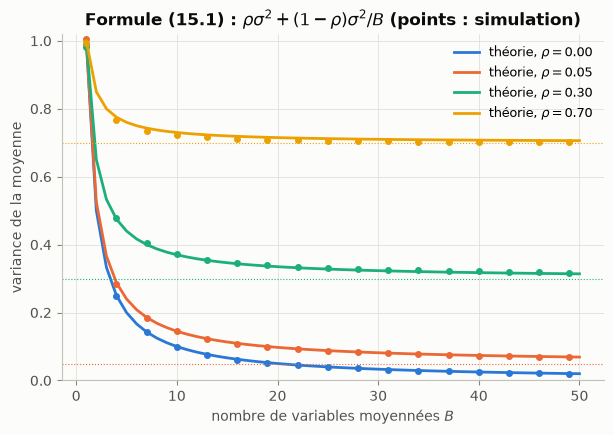

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for c, rho in zip(COLORS, rhos):
    ax.plot(B_grille, rf.variance_moyenne_correlee(sigma2, rho, B_grille), color=c,
            label=r"théorie, $\rho=%.2f$" % rho)
    ax.plot(B_grille[::3], var_emp[rho][::3], "o", color=c, ms=4)
    ax.axhline(rho * sigma2, color=c, lw=0.8, ls=":")
ax.set_xlabel("nombre de variables moyennées $B$")
ax.set_ylabel("variance de la moyenne")
ax.set_title(r"Formule (15.1) : $\rho\sigma^2 + (1-\rho)\sigma^2/B$ (points : simulation)")
ax.set_ylim(0, 1.02)
ax.legend()
plt.show()

Les pointillés horizontaux indiquent le plancher $\rho\sigma^2$. Avec $\rho=0{,}7$, moyenner
50 variables ne divise la variance que par environ $1{,}4$ ; avec $\rho=0{,}05$ on la divise
par plus de 10.

## 3. L'idée des forêts aléatoires

Les arbres bagués sont fortement corrélés : ils sont construits sur des échantillons
bootstrap qui partagent en moyenne 63 % de leurs observations, et les variables
« fortes » sont choisies aux premières coupures de presque tous les arbres. Pour
**décorréler** les arbres, la forêt aléatoire ajoute une seconde source d'aléa :

> avant **chaque** coupure, on tire au hasard $m\le p$ variables parmi les $p$, et l'on ne
> cherche la meilleure coupure que parmi ces $m$ candidates.

Valeurs typiques : $m=\lfloor\sqrt p\rfloor$ en classification, $m=\lfloor p/3\rfloor$ en
régression, parfois même $m=1$. Le cas $m=p$ redonne exactement le bagging.

### Algorithme 15.1 (forêt aléatoire, régression ou classification)

1. Pour $b=1$ à $B$ :
   - (a) tirer un échantillon bootstrap $\mathbf Z^*$ de taille $N$ ;
   - (b) faire pousser un arbre $T_b$ sur $\mathbf Z^*$ en répétant récursivement, pour
     chaque nœud terminal, tant que l'effectif minimal $n_{\min}$ n'est pas atteint :
     1. tirer $m$ variables au hasard parmi les $p$ ;
     2. choisir la meilleure variable et le meilleur seuil parmi ces $m$ ;
     3. couper le nœud en deux nœuds fils.
2. Renvoyer l'ensemble $\{T_b\}_{b=1}^B$.

Prédiction en $x$ : en régression, $\hat f^B_{\rm rf}(x)=\frac1B\sum_{b=1}^B T(x;\Theta_b)$
(éq. (15.2)), où $\Theta_b$ résume tout ce qui définit le $b$-ième arbre (variables de
coupure, seuils, valeurs des feuilles) ; en classification, vote majoritaire des classes
prédites $\hat C_b(x)$.

### Le critère de coupure

Notre implémentation (module `esl/ch15_forets.py`, classe `ArbreAleatoire`) utilise le
critère des moindres carrés de la section 9.2.2. Dans un nœud contenant $n$ observations
de somme $S=\sum_i y_i$, la somme des carrés des écarts vaut
$\mathrm{SCE}=\sum_i y_i^2 - S^2/n$. Si une coupure envoie $n_G$ observations (de somme
$S_G$) à gauche et $n_D$ (de somme $S_D$) à droite, les termes $\sum y_i^2$ se
compensent et la **réduction** de SCE vaut
$$\Delta=\mathrm{SCE}-\mathrm{SCE}_G-\mathrm{SCE}_D=\frac{S_G^2}{n_G}+\frac{S_D^2}{n_D}-\frac{S^2}{n}.$$
Après tri des valeurs de la variable, les $S_G$ de toutes les coupures possibles
s'obtiennent par une **somme cumulée** : la recherche est en $O(n\log n)$ par variable.

> **Remarque (classification binaire).** Pour $y\in\{0,1\}$ et une proportion
> $\hat p=S/n$ de 1 dans le nœud, on a $\mathrm{SCE}=n\hat p(1-\hat p)$ tandis que
> l'indice de Gini du nœud vaut $2\hat p(1-\hat p)$. La réduction de SCE est donc la
> **moitié** de la réduction de l'indice de Gini pondéré par les effectifs : un arbre
> de régression sur la variable 0/1 choisit exactement les coupures de Gini. La valeur
> d'une feuille est la proportion de 1 et la classe prédite est 1 si elle dépasse $1/2$.

Le cœur de la recherche de coupure tient en quelques lignes :

In [4]:
import inspect
print(inspect.getsource(rf._meilleure_coupure))

def _meilleure_coupure(x, y, nmin):
    """Meilleure coupure ``x <= s`` pour une variable : maximise la réduction
    de la somme des carrés des écarts. Retourne ``(gain, seuil)`` ou ``None``."""
    o = np.argsort(x, kind="mergesort")
    xs, ys = x[o], y[o]
    n = len(ys)
    cs = np.cumsum(ys)
    S = cs[-1]
    nl = np.arange(1, n)
    sl = cs[:-1]
    nr = n - nl
    sr = S - sl
    valide = (xs[:-1] < xs[1:]) & (nl >= nmin) & (nr >= nmin)
    if not valide.any():
        return None
    gain = sl ** 2 / nl + sr ** 2 / nr - S ** 2 / n
    gain = np.where(valide, gain, -np.inf)
    i = int(np.argmax(gain))
    return gain[i], 0.5 * (xs[i] + xs[i + 1])



### Une illustration en dimension 1

Sur un petit problème de régression, comparons un arbre profond seul et la moyenne de
200 arbres construits sur des échantillons bootstrap ($p=1$, donc ici forêt = bagging).

In [5]:
rng = np.random.RandomState(0)
x1 = np.sort(rng.rand(80))
y1 = np.sin(2 * np.pi * x1) + 0.4 * rng.randn(80)
grille = np.linspace(0, 1, 400)[:, None]

arbre_seul = rf.ArbreAleatoire(nmin=3).fit(x1[:, None], y1)
foret_1d = rf.ForetAleatoire(B=200, nmin=3, seed=0).fit(x1[:, None], y1)
P1 = foret_1d.predictions_arbres(grille)

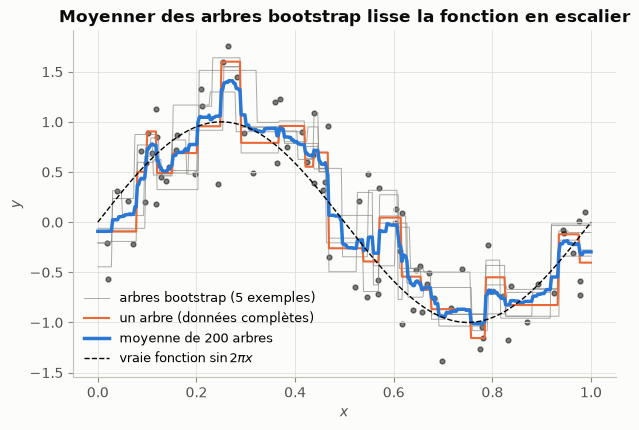

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for b in range(5):
    ax.plot(grille[:, 0], P1[b], color=GRAY, lw=0.7, alpha=0.7,
            label="arbres bootstrap (5 exemples)" if b == 0 else None)
ax.plot(grille[:, 0], arbre_seul.predict(grille), color=ORANGE, lw=1.5, label="un arbre (données complètes)")
ax.plot(grille[:, 0], P1.mean(axis=0), color=BLUE, lw=2.5, label="moyenne de 200 arbres")
ax.plot(grille[:, 0], np.sin(2 * np.pi * grille[:, 0]), "k--", lw=1, label=r"vraie fonction $\sin 2\pi x$")
ax.scatter(x1, y1, s=12, color="k", alpha=0.5)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Moyenner des arbres bootstrap lisse la fonction en escalier")
ax.legend(loc="lower left")
plt.show()

Chaque arbre est une fonction en escalier très irrégulière ; leur moyenne est bien plus
lisse et plus proche de la vraie fonction : c'est la réduction de variance à l'œuvre.

## 4. Les données spam

Les données spam (déjà rencontrées aux chapitres 9 et 10) comptent $N=4601$ courriels
décrits par $p=57$ variables (fréquences de mots et de caractères, longueurs de suites
de majuscules). Le livre utilise un ensemble test de 1536 courriels ; faute de
l'indicateur d'origine, nous tirons au hasard (graine fixée) une séparation de même
taille.

In [7]:
spam = datasets.load_spam()
Xtr, ytr, Xte, yte = rf.separer_spam(spam)
p = Xtr.shape[1]
print("apprentissage :", Xtr.shape, " test :", Xte.shape, " proportion de spams : %.3f" % ytr.mean())
print("m par défaut (classification) : floor(sqrt(57)) =", int(np.sqrt(p)))

apprentissage : (3065, 57)  test : (1536, 57)  proportion de spams : 0.389
m par défaut (classification) : floor(sqrt(57)) = 7


Ajustons notre forêt « maison » avec $B=300$ arbres, $m=\lfloor\sqrt{57}\rfloor=7$ et
$n_{\min}=1$ (arbres poussés jusqu'au bout, recommandation de la section 15.3).

In [8]:
t0 = time.time()
foret = rf.ForetAleatoire(B=300, m=7, nmin=1, classification=True, seed=0).fit(Xtr, ytr)
print("temps d'ajustement : %.1f s" % (time.time() - t0))
P_te = foret.predictions_arbres(Xte)   # votes 0/1 de chaque arbre sur le test
P_tr = foret.predictions_arbres(Xtr)   # votes sur l'apprentissage (pour l'OOB)
print("erreur test de la forêt : %.4f" % np.mean(foret.predict(Xte) != yte))

temps d'ajustement : 10.4 s


erreur test de la forêt : 0.0469


Comparons l'erreur de la forêt à celle des arbres qui la composent : chaque arbre, pris
isolément, est un classifieur médiocre.

In [9]:
err_arbres = np.mean(P_te != yte[None, :], axis=1)
nb_feuilles = [a.n_feuilles for a in foret.arbres]
print("erreur test moyenne d'un arbre : %.4f (min %.4f, max %.4f)"
      % (err_arbres.mean(), err_arbres.min(), err_arbres.max()))
print("nombre moyen de feuilles par arbre : %.0f" % np.mean(nb_feuilles))

erreur test moyenne d'un arbre : 0.1112 (min 0.0827, max 0.1465)
nombre moyen de feuilles par arbre : 206


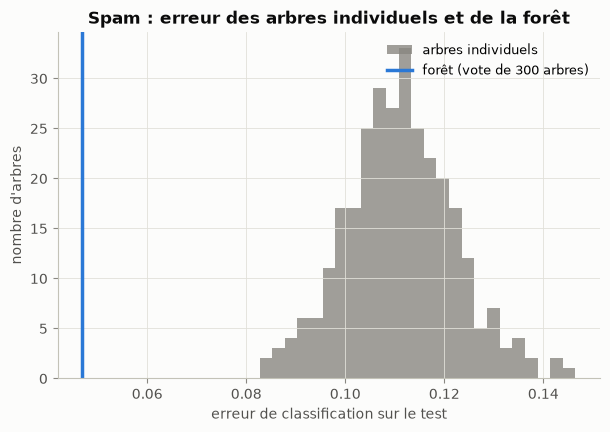

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(err_arbres, bins=25, color=GRAY, alpha=0.8, label="arbres individuels")
ax.axvline(np.mean(foret.predict(Xte) != yte), color=BLUE, lw=2.5, label="forêt (vote de 300 arbres)")
ax.set_xlabel("erreur de classification sur le test")
ax.set_ylabel("nombre d'arbres")
ax.set_title("Spam : erreur des arbres individuels et de la forêt")
ax.legend()
plt.show()

À titre de contrôle, comparons à l'implémentation de scikit-learn
(`RandomForestClassifier`), utilisée ici uniquement comme référence.

In [11]:
from sklearn.ensemble import RandomForestClassifier
sk = RandomForestClassifier(n_estimators=300, max_features=7, n_jobs=-1, random_state=0).fit(Xtr, ytr)
print("erreur test scikit-learn : %.4f" % np.mean(sk.predict(Xte) != yte))
print("corrélation des importances (maison / scikit-learn) : %.3f"
      % np.corrcoef(foret.importance_gini, sk.feature_importances_)[0, 1])

erreur test scikit-learn : 0.0462
corrélation des importances (maison / scikit-learn) : 0.996


Les deux implémentations donnent des erreurs très proches (de l'ordre de 5 %, comme le
4,88 % annoncé dans le livre) et des importances quasi identiques.

## 5. Erreur *out-of-bag* (section 15.3.1)

Une observation $z_i$ a une probabilité $(1-1/N)^N\approx e^{-1}\approx 0{,}368$ de ne
**pas** figurer dans un échantillon bootstrap donné : chaque arbre laisse de côté environ
un tiers des données. D'où l'idée :

> pour chaque observation $z_i=(x_i,y_i)$, construire son prédicteur en n'agrégeant
> **que les arbres dont l'échantillon bootstrap ne contient pas $z_i$** ; l'erreur
> commise sur $y_i$ par ce prédicteur est l'erreur *out-of-bag* (OOB).

Aucune observation n'est donc jamais prédite par un arbre qui l'a vue : l'erreur OOB est
une estimation honnête de l'erreur de généralisation, obtenue **gratuitement** pendant
l'ajustement. L'exercice 15.2 montre qu'elle coïncide, quand $B\to\infty$, avec une
validation croisée « leave-one-out » ($N$ blocs).

In [12]:
frac_oob = (~foret.dans_sac).mean()
N = len(ytr)
print("fraction hors sac observée : %.4f   (1-1/N)^N = %.4f   1/e = %.4f"
      % (frac_oob, (1 - 1 / N) ** N, np.exp(-1)))

fraction hors sac observée : 0.3685   (1-1/N)^N = 0.3678   1/e = 0.3679


Calculons l'erreur OOB et l'erreur test en fonction du nombre d'arbres $b$ (fonctions
`erreur_oob_cumulee` et `erreur_test_cumulee`) : c'est la figure 15.4 du livre.

In [13]:
oob = rf.erreur_oob_cumulee(P_tr, foret.dans_sac, ytr)
test = rf.erreur_test_cumulee(P_te, yte)
print("avec 300 arbres : OOB = %.4f, test = %.4f" % (oob[-1], test[-1]))

avec 300 arbres : OOB = 0.0509, test = 0.0469


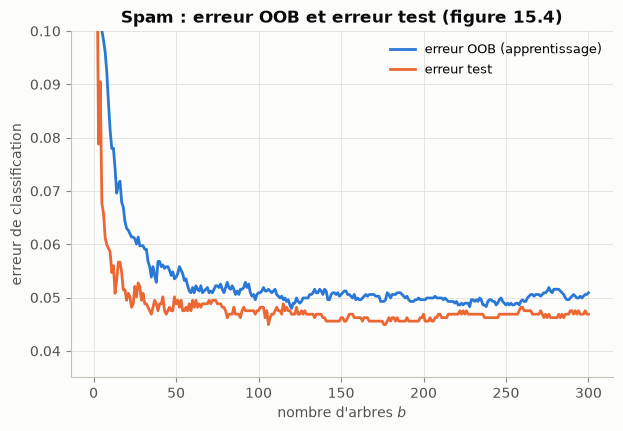

In [14]:
b = np.arange(1, foret.B + 1)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(b, oob, color=BLUE, label="erreur OOB (apprentissage)")
ax.plot(b, test, color=ORANGE, label="erreur test")
ax.set_ylim(0.035, 0.1)
ax.set_xlabel("nombre d'arbres $b$")
ax.set_ylabel("erreur de classification")
ax.set_title("Spam : erreur OOB et erreur test (figure 15.4)")
ax.legend()
plt.show()

Les deux courbes se stabilisent rapidement (quelques dizaines à 200 arbres) au même
niveau : l'erreur OOB permet de **choisir $B$ et de régler $m$ sans ensemble test ni
validation croisée** - on peut arrêter l'ajustement dès que l'erreur OOB se stabilise.
(Pour les petites valeurs de $b$, l'erreur OOB est pessimiste : chaque observation n'est
alors prédite que par environ $b/3$ arbres.)

## 6. Comparaison avec le bagging et le boosting sur spam (figure 15.1)

Pour tracer des courbes jusqu'à 1000 arbres (1500 pour le boosting, au lieu des 2500 du livre) en un temps
raisonnable, nous utilisons ici scikit-learn : `RandomForestClassifier` avec
`max_features=57` pour le **bagging** et `max_features=7` pour la forêt, et
`GradientBoostingClassifier` avec des arbres à 5 feuilles pour le **boosting** du
chapitre 10 (que nous ne recodons pas ici).